# 01 · Exploración de los datos

*Segundos contra vidas* · Hackathon de Datos 2026 · ITM

Cada parte: código → conclusión → decisión.

## 0 · Configuración

In [40]:
import os, sys, unicodedata, re
from pathlib import Path

raiz = Path.cwd()
while not (raiz / "src" / "fuentes.py").exists():
    if raiz.parent == raiz:
        raise FileNotFoundError(f"No encontré el proyecto. El notebook está en: {Path.cwd()}")
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, str(raiz))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.descarga import leer

pd.set_option("display.max_columns", 40)
print("Proyecto:", raiz)

Proyecto: C:\Users\crist\Documents\segundos-contra-vidas


In [4]:
# Nombres de columnas uniformes: minúscula, sin tildes, con guion bajo
def _arreglar_texto(s):
    for codif in ("latin-1", "cp1252"):
        try:
            return s.encode(codif).decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            pass
    return s

def normalizar_columnas(df):
    nuevas = []
    for c in df.columns:
        c = unicodedata.normalize("NFKD", _arreglar_texto(str(c))).encode("ascii", "ignore").decode()
        nuevas.append(re.sub(r"[^0-9a-z]+", "_", c.lower()).strip("_"))
    df.columns = nuevas
    return df

## 1 · Incidentes viales · base del ITM (2008–2025)

#### 1.1 Carga y estructura

In [5]:
itm = normalizar_columnas(leer("incidentes_itm"))
print(itm.shape)
print(list(itm.columns))
itm.head()

(702540, 13)
['llave', 'ano', 'fecha_incidente', 'hora_incidente', 'clase_incidente', 'gravedad_incidente', 'direccion_interpolada', 'latitud', 'longitud', 'codigo_comuna_planeacion', 'comuna_planeacion', 'codigo_barrio_planeacion', 'barrio_planeacion']


,llave,ano,fecha_incidente,hora_incidente,clase_incidente,gravedad_incidente,direccion_interpolada,latitud,longitud,codigo_comuna_planeacion,comuna_planeacion,codigo_barrio_planeacion,barrio_planeacion
0,1,2008,2008-01-01,00:10:00,Choque,SOLO DAÑOS,Carrera 40 Con Calle 64,6.256148,-75.554313,8,Villa Hermosa,0803,San Miguel
1,2,2008,2008-01-01,00:30:00,Otro,HERIDO,Calle 13 A Con Carrera 5,NaN,NaN,N/D,N/D,Sin inf,Sin inf
2,3,2008,2008-01-01,00:35:00,Choque,HERIDO,Calle 104 Con Carrera 65,6.301501,-75.566227,5,Castilla,0509,Boyacá
3,4,2008,2008-01-01,01:00:00,Choque,HERIDO,Calle 54 Con Carrera 83,6.269136,-75.599001,12,La América,1213,Calasanz Parte Alta
4,5,2008,2008-01-01,01:20:00,Otro,HERIDO,Calle 110 Con Carrera 43 A,6.298791,-75.548047,1,Popular,0103,Popular


#### 1.2 Incidentes por año

In [6]:
itm["ano"].value_counts().sort_index()

ano
2008    37672
2009    38210
2010    38539
2011    41779
2012    46439
2013    48601
2014    45609
2015    46061
2016    47300
2017    46100
2018    43307
2019    45792
2020    31931
2021    40599
2022    38720
2023    24511
2024    22562
2025    18808
Name: count, dtype: int64

#### 1.3 Gravedad por año

In [7]:
grav_anio = pd.crosstab(itm["ano"], itm["gravedad_incidente"])
grav_anio

gravedad_incidente,HERIDO,MUERTO,SOLO DAÑOS
ano,,,
2008,14246,179,23247
2009,17160,150,20900
2010,17032,131,21376
2011,19088,166,22525
2012,22865,154,23420
2013,25950,149,22502
2014,25686,136,19787
2015,25911,150,20000
2016,26718,138,20444


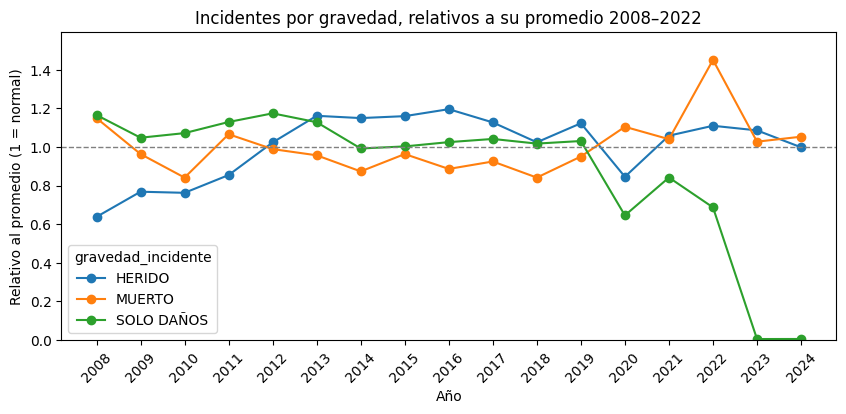

In [16]:
g = grav_anio.loc[:2024]
referencia = g.loc[2008:2022].mean()   # promedio antes del cambio de registro

relativo = g / referencia

ax = relativo.plot(marker="o", figsize=(10, 4), title="Incidentes por gravedad, relativos a su promedio 2008–2022")
ax.axhline(1, color="gray", ls="--", lw=1)
ax.set_ylim(0, 1.4)
ax.set_xticks(relativo.index); ax.tick_params(axis="x", rotation=45)
ax.set_xlabel("Año"); ax.set_ylabel("Relativo al promedio (1 = normal)")
ax.set_ylim(0, relativo.max().max() * 1.1)
plt.show()

#### 1.4 Datos faltantes

In [19]:
itm.isna().mean().mul(100).round(2).sort_values(ascending=False)

longitud                    6.37
latitud                     6.37
codigo_barrio_planeacion    1.66
barrio_planeacion           1.66
direccion_interpolada       1.58
clase_incidente             0.00
hora_incidente              0.00
fecha_incidente             0.00
ano                         0.00
llave                       0.00
gravedad_incidente          0.00
comuna_planeacion           0.00
codigo_comuna_planeacion    0.00
dtype: float64

In [26]:
direcciones_999 = itm["direccion_interpolada"].astype(str).str.contains("999", na=False)
print("Direcciones con '999':", direcciones_999.sum())
print(itm.loc[direcciones_999, "direccion_interpolada"].value_counts().head(10))

print("\nValores 'N/D' por columna:")
print((itm.astype(str) == "N/D").sum().loc[lambda s: s > 0])

fuera = itm["latitud"].notna() & ~(itm["latitud"].between(6.1, 6.4) & itm["longitud"].between(-75.7, -75.5))
print("\nCoordenadas fuera de Medellín:", fuera.sum())

Direcciones con '999': 4265
direccion_interpolada
CALLE 999 CON CARRERA 999     2656
Carrera 999 Con Calle 999      648
Calle 999 Con Carrera 999      214
CALLE 999 CON CARRERA 99        26
Tramo 15 Con Kilometro 999      19
Tramo 18 Con Kilometro 999      18
Tramo 4 Con Kilometro 999       15
CALLE 30 CON CARRERA 999        14
Tramo 9 Con Kilometro 999       14
Tramo 8 Con Kilometro 999       12
Name: count, dtype: int64

Valores 'N/D' por columna:
codigo_comuna_planeacion    28154
comuna_planeacion           28154
dtype: int64

Coordenadas fuera de Medellín: 225


In [29]:
itm_limpio = itm.copy()
itm_limpio.loc[direcciones_999, "direccion_interpolada"] = pd.NA
itm_limpio = itm_limpio.replace("N/D", pd.NA)
itm_limpio.loc[fuera, ["latitud", "longitud"]] = pd.NA
faltantes = pd.DataFrame({
    "antes_%": itm.isna().mean().mul(100),
    "despues_%": itm_limpio.isna().mean().mul(100),
}).round(2).sort_values("despues_%", ascending=False)
faltantes

,antes_%,despues_%
longitud,6.37,6.41
latitud,6.37,6.41
comuna_planeacion,0.00,4.01
codigo_comuna_planeacion,0.00,4.01
direccion_interpolada,1.58,2.19
barrio_planeacion,1.66,1.66
codigo_barrio_planeacion,1.66,1.66
clase_incidente,0.00,0.00
ano,0.00,0.00
llave,0.00,0.00


In [31]:
#Incidentes graves sin ubicación posible
g = itm_limpio[itm_limpio["gravedad_incidente"].isin(["HERIDO", "MUERTO"])]
sin_coord = g["latitud"].isna()
sin_dir = g["direccion_interpolada"].isna()

print(f"Graves sin coordenadas: {sin_coord.mean()*100:.2f} %")
print(f"Graves sin dirección:   {sin_dir.mean()*100:.2f} %")
print(f"Graves SIN NINGUNA:     {(sin_coord & sin_dir).mean()*100:.2f} %  ({(sin_coord & sin_dir).sum()} incidentes)")

Graves sin coordenadas: 7.53 %
Graves sin dirección:   2.53 %
Graves SIN NINGUNA:     2.53 %  (10191 incidentes)


#### 1.5 Incidentes graves por hora del día

In [20]:
graves = itm[itm["gravedad_incidente"].isin(["HERIDO", "MUERTO"])].copy()
graves["hora"] = pd.to_datetime(graves["hora_incidente"].astype(str), format="%H:%M:%S", errors="coerce").dt.hour

por_hora = pd.crosstab(graves["hora"], graves["gravedad_incidente"])
por_hora["pct_muertos"] = (por_hora["MUERTO"] / por_hora.sum(axis=1) * 100).round(2)
por_hora

gravedad_incidente,HERIDO,MUERTO,pct_muertos
hora,,,
0,7032,99,1.39
1,4806,74,1.52
2,4043,84,2.04
3,3395,98,2.81
4,5091,111,2.13
5,13257,165,1.23
6,23206,128,0.55
7,25715,131,0.51
8,19767,94,0.47


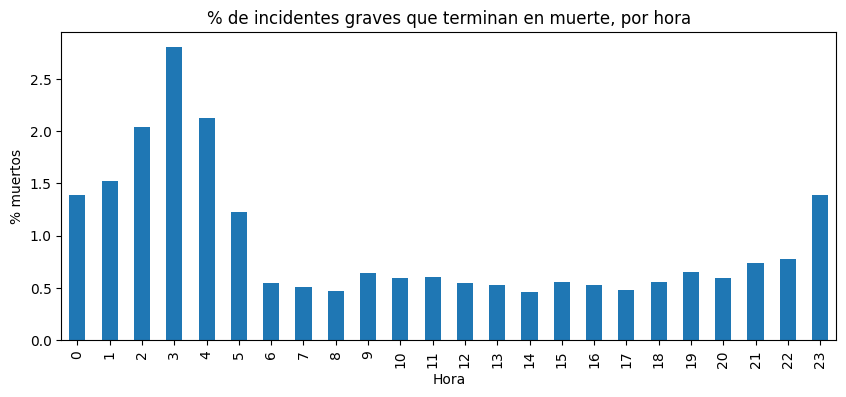

In [21]:
ax = por_hora["pct_muertos"].plot(kind="bar", figsize=(10, 4), title="% de incidentes graves que terminan en muerte, por hora")
ax.set_xlabel("Hora"); ax.set_ylabel("% muertos")
plt.show()

#### 1.6 Clase de incidente (solo graves)

In [22]:
pd.crosstab(graves["clase_incidente"], graves["gravedad_incidente"], margins=True)

gravedad_incidente,HERIDO,MUERTO,All
clase_incidente,,,
Atropello,73702,961,74663
Caida Ocupante,53465,89,53554
Choque,162358,1524,163882
Incendio,55,1,56
Otro,89384,137,89521
Volcamiento,21409,50,21459
All,400373,2762,403135


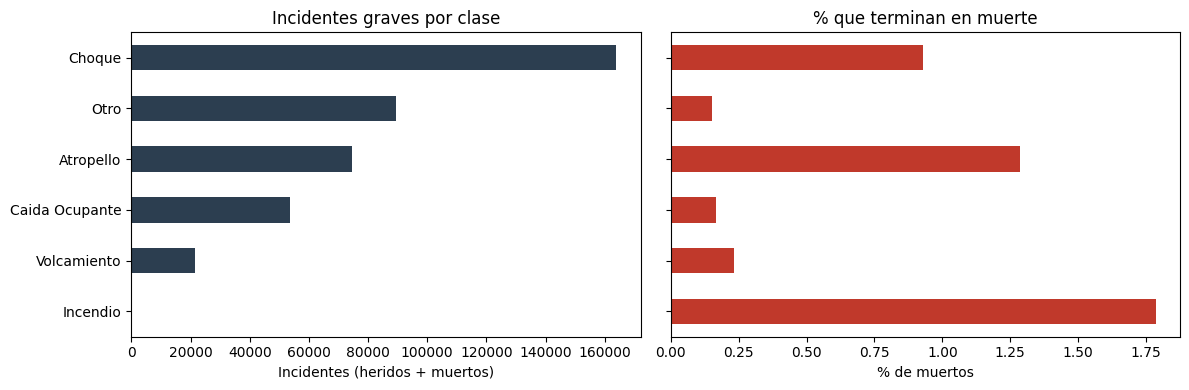

In [24]:
clase = pd.crosstab(graves["clase_incidente"], graves["gravedad_incidente"])
clase["total_graves"] = clase["HERIDO"] + clase["MUERTO"]
clase["pct_muertos"] = clase["MUERTO"] / clase["total_graves"] * 100
clase = clase.sort_values("total_graves")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

clase["total_graves"].plot(kind="barh", ax=ax1, color="#2C3E50")
ax1.set_title("Incidentes graves por clase")
ax1.set_xlabel("Incidentes (heridos + muertos)"); ax1.set_ylabel("")

clase["pct_muertos"].plot(kind="barh", ax=ax2, color="#C0392B")
ax2.set_title("% que terminan en muerte")
ax2.set_xlabel("% de muertos")

plt.tight_layout(); plt.show()

#### 1.7 Vías más frecuentes en las direcciones (solo graves)

In [25]:
graves["via_principal"] = graves["direccion_interpolada"].astype(str).str.split(" Con ").str[0].str.strip()
graves["via_principal"].value_counts().head(30)

via_principal
Calle 44                     7149
nan                          6949
Carrera 80                   6333
Carrera 52                   5937
Carrera 65                   5558
Carrera 64 C                 5322
Carrera 63                   4123
Carrera 46                   4109
Carrera 50                   3950
Calle 58                     3875
Calle 50                     3846
Carrera 49                   3271
Calle 49                     3254
Carrera 48                   3106
Calle 67                     2983
Calle 80                     2726
Carrera 62                   2718
Calle 30                     2717
Calle 65                     2480
Calle 33                     2343
Carrera 43 A                 2313
Carrera 57                   2300
Carrera 51                   2122
Calle 10                     2085
CALLE 999 CON CARRERA 999    2033
Carrera 45                   2013
Calle 52                     1999
Carrera 70                   1979
Calle 57                     1881


### Conclusión

**1.1 Estructura.** La base del ITM tiene 702.540 incidentes, de enero de 2008 a agosto de 2025, en 13 columnas: fecha, hora, clase, gravedad, dirección, coordenadas, comuna y barrio. No indica si hubo moto o peatón; ese dato debe venir de otras fuentes.

**1.2 y 1.3 Evolución por gravedad.** Desde 2023 los incidentes de solo daños pasan de unos 20.000 por año a menos de 100, mientras heridos y muertos se mantienen estables. La caída del total en 2023 se debe a un probable cambio en el registro, no a una mejora real. Los incidentes graves sí son comparables en todo el periodo, con tres matices:
- Los heridos crecen cerca de 80 % entre 2008 y 2013 (de 14.246 a 25.950) y desde entonces se estabilizan.
- 2020 cae en todas las gravedades por la pandemia.
- 2022 es el año más letal de la serie: 226 muertos, cerca de 45 % por encima del promedio 2008–2022 (unos 156).
- 2025 solo tiene datos hasta agosto, así que no es comparable como año completo.

**1.4 Datos faltantes.** Además de los vacíos explícitos, la base usa valores de relleno: "CALLE 999 CON CARRERA 999" en la dirección, "N/D" en la comuna y coordenadas fuera de Medellín. Al tratarlos como faltantes, la comuna pasa de 0 % a 4,0 % y la dirección de 1,6 % a 2,2 %. Entre los incidentes graves, el 7,5 % no tiene coordenadas y el 2,5 % (10.191) no tiene ni dirección ni coordenadas, porque las coordenadas se interpolaron a partir de la dirección. Solo ese 2,5 % no se puede asignar a un corredor.

**1.5 Letalidad por hora.** Entre las 6 a. m. y las 8 p. m., cerca del 0,5 % de los incidentes graves termina en muerte. De madrugada la letalidad sube y llega a 2,8 % a las 3 a. m., más de 5 veces la del día. Es coherente con la hipótesis de mayor velocidad nocturna, pero no la prueba: de noche también influyen el alcohol, el cansancio y la visibilidad.

**1.6 Clase de incidente.** De los 403.135 incidentes graves, el 0,69 % (2.762) fue mortal. Los choques son los más frecuentes y concentran el 55 % de las muertes (1.524; letalidad de 0,93 %). Los atropellos son menos frecuentes pero más letales (1,29 %) y concentran el 35 % (961). Entre los dos suman el 90 % de las muertes. El 1,79 % de "Incendio" no es confiable: son 56 casos y 1 muerte.

**1.7 Vías más frecuentes.** Las vías con más incidentes graves coinciden con los corredores con datos de velocidad: Calle 44 (San Juan, la primera con 7.149), Carrera 80 (Avenida 80), Carrera 46 (Oriental), Calle 30, Calle 33 (Avenida 33) y Carrera 43 A (El Poblado). Las direcciones usan el número de la vía y no el nombre de la avenida, así que la asignación a corredores debe hacerse con ese formato.

### Decisión

-  todo el análisis usa solo incidentes graves (heridos y muertos).
-  2025 no se compara como año completo.
-  los valores de relleno se tratan como faltantes. El 2,5 % de los graves sin ubicación no se asigna a corredor, pero no se elimina.
-  la hora del incidente entra a los modelos como variable de control.

## 2 · Víctimas en incidentes viales · MEData

#### 2.1 Carga y estructura

In [32]:
vic = normalizar_columnas(leer("victimas_medata"))
print(vic.shape)
print(list(vic.columns))
vic.head()

Descargando victimas_medata (~54 MB) desde la URL…
(1048317, 19)
['gravedad_victima', 'fecha_incidente', 'hora_incidente', 'clase_incidente', 'direccion_incidente', 'sexo', 'edad', 'condicion', 'mes', 'dia', 'num_dia', 'hora', 'grupo_edad', 'ano', 'radicado', 'latitud', 'longitud', 'comuna', 'barrio']


,gravedad_victima,fecha_incidente,hora_incidente,clase_incidente,direccion_incidente,sexo,edad,condicion,mes,dia,num_dia,hora,grupo_edad,ano,radicado,latitud,longitud,comuna,barrio
0,Heridos,1/01/2014,00:15:00,Otro,CR 49 CL 72,M,17,Motociclista,Ene,Mié,1.0,0,10 - 19,2014.0,1423940,"6,26691466","-75,5590994",04 - Aranjuez,Manrique Central No. 1
1,Heridos,1/01/2014,00:30:00,Atropello,CR 46 CL 98,M,20,Motociclista,Ene,Mié,1.0,0,20 - 29,2014.0,1423921,"6,289353458","-75,55329197",01 - Popular,Moscú No. 2
2,Heridos,1/01/2014,00:30:00,Atropello,CR 46 CL 98,F,18,Peatón,Ene,Mié,1.0,0,10 - 19,2014.0,1423921,"6,289353458","-75,55329197",01 - Popular,Moscú No. 2
3,Heridos,1/01/2014,00:37:00,Atropello,CL 32 CR 84,M,19,Motociclista,Ene,Mié,1.0,0,10 - 19,2014.0,1423849,"6,234327372","-75,60761079",16 - Belén,Las Mercedes
4,Heridos,1/01/2014,00:37:00,Atropello,CL 32 CR 84,M,39,Peatón,Ene,Mié,1.0,0,30 - 39,2014.0,1423849,"6,234327372","-75,60761079",16 - Belén,Las Mercedes


#### 2.2 Víctimas por año (¿archivo recortado?)

In [33]:
print("Filas:", len(vic), "· límite de Excel: 1.048.576")
vic["ano"].value_counts().sort_index()

Filas: 1048317 · límite de Excel: 1.048.576


ano
2014.0    31411
2015.0    32622
2016.0    33791
2017.0    31658
2018.0    29082
2019.0    31876
2020.0    23676
2021.0    21727
Name: count, dtype: int64

#### 2.3 Condición de la víctima por gravedad

In [34]:
pd.crosstab(vic["condicion"], vic["gravedad_victima"], margins=True).sort_values("All", ascending=False)

gravedad_victima,Heridos,Muertos,All
condicion,,,
All,233894,1949,235843
Motociclista,141442,725,142167
Peatón,31505,890,32395
Acompañante de Motocicleta,28773,129,28902
Pasajero,13483,41,13524
Acompañante de motocicleta,7228,29,7257
Conductor,6154,39,6193
Ciclista,5309,96,5405


#### 2.4 ¿Sirve el radicado para unir con los incidentes?

In [35]:
print("Radicados vacíos (%):", round(vic["radicado"].isna().mean() * 100, 2))
print("Víctimas por radicado (promedio):", round(vic.groupby("radicado").size().mean(), 2))
print("Columnas de incidentes ITM con 'radicado':", [c for c in itm.columns if "radic" in c])

Radicados vacíos (%): 77.5
Víctimas por radicado (promedio): 1.25
Columnas de incidentes ITM con 'radicado': []


In [36]:
# 2.5 Limpieza: filas vacías, fechas, condición
vic = vic[vic["ano"].notna()].copy()
print("Víctimas reales:", len(vic))

vic["fecha"] = pd.to_datetime(vic["fecha_incidente"], dayfirst=True, errors="coerce")
print("Desde", vic["fecha"].min().date(), "hasta", vic["fecha"].max().date())
print("Meses con datos en 2021:", sorted(vic.loc[vic["ano"] == 2021, "fecha"].dt.month.dropna().unique()))

vic["condicion"] = vic["condicion"].replace({"Acompañante de Motocicleta": "Acompañante de motocicleta"})
vic["actor"] = vic["condicion"].replace({"Motociclista": "Moto", "Acompañante de motocicleta": "Moto"})

muertos = vic[vic["gravedad_victima"] == "Muertos"]
print("\n% de muertos por actor:")
print((muertos["actor"].value_counts(normalize=True) * 100).round(1))

# Comparar con la base del ITM (víctimas ≥ incidentes, porque un incidente puede tener varios muertos)
comp = pd.DataFrame({
    "muertos_victimas": muertos.groupby("ano").size(),
    "incidentes_mortales_itm": itm[itm["gravedad_incidente"] == "MUERTO"].groupby("ano").size(),
}).loc[2014:2021]
comp["razon"] = (comp["muertos_victimas"] / comp["incidentes_mortales_itm"]).round(2)
comp

Víctimas reales: 235843
Desde 2014-01-01 hasta 2021-09-30
Meses con datos en 2021: [np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9)]

% de muertos por actor:
actor
Peatón       45.7
Moto         45.3
Ciclista      4.9
Pasajero      2.1
Conductor     2.0
Name: proportion, dtype: float64


,muertos_victimas,incidentes_mortales_itm,razon
ano,,,
2014.0,290.0,136,2.13
2015.0,274.0,150,1.83
2016.0,271.0,138,1.96
2017.0,258.0,144,1.79
2018.0,239.0,131,1.82
2019.0,247.0,148,1.67
2020.0,196.0,172,1.14
2021.0,174.0,162,1.07


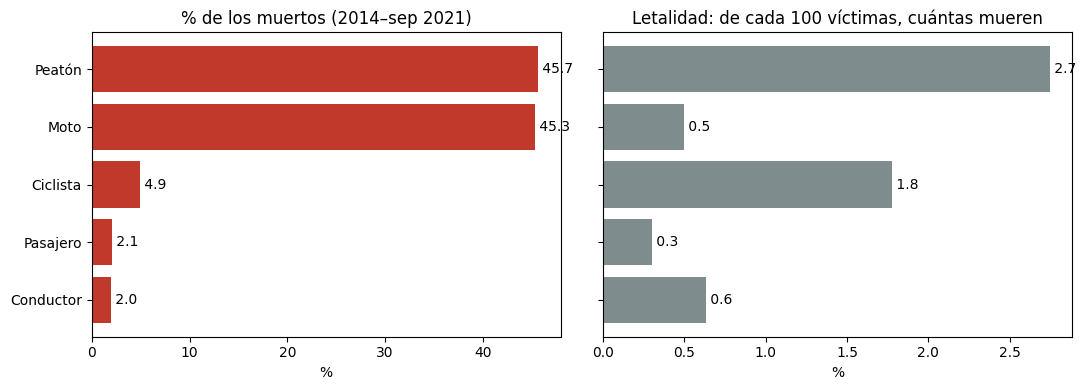

,total,muertos,pct_muertos,letalidad
actor,,,,
Conductor,6193,39,2.00,0.63
Pasajero,13524,41,2.10,0.30
Ciclista,5405,96,4.93,1.78
Moto,178326,883,45.31,0.50
Peatón,32395,890,45.66,2.75


In [37]:
# 2.6 Muertos por actor y letalidad
por_actor = vic.groupby("actor")["gravedad_victima"].agg(
    total="size", muertos=lambda s: (s == "Muertos").sum())
por_actor["pct_muertos"] = por_actor["muertos"] / por_actor["muertos"].sum() * 100
por_actor["letalidad"] = por_actor["muertos"] / por_actor["total"] * 100
por_actor = por_actor.sort_values("pct_muertos")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
ax1.barh(por_actor.index, por_actor["pct_muertos"], color="#c0392b")
ax1.set_title("% de los muertos (2014–sep 2021)")
ax1.set_xlabel("%")
ax2.barh(por_actor.index, por_actor["letalidad"], color="#7f8c8d")
ax2.set_title("Letalidad: de cada 100 víctimas, cuántas mueren")
ax2.set_xlabel("%")
for ax, col in [(ax1, "pct_muertos"), (ax2, "letalidad")]:
    for i, v in enumerate(por_actor[col]):
        ax.text(v, i, f" {v:.1f}", va="center")
plt.tight_layout(); plt.show()
por_actor.round(2)

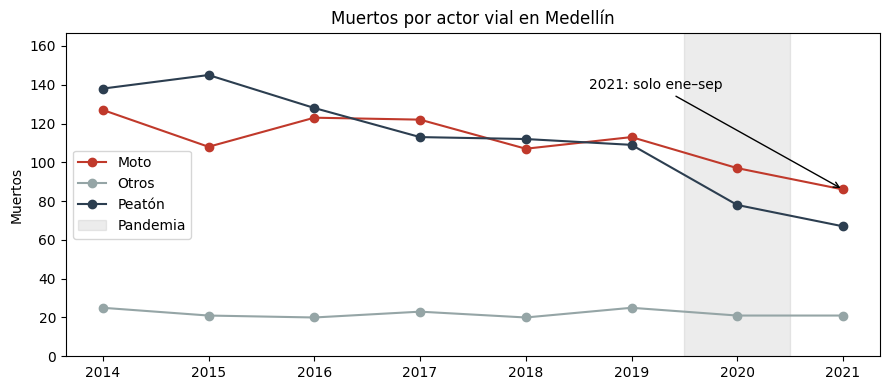

In [38]:
# 2.7 Evolución de los muertos por actor
vic["actor_graf"] = vic["actor"].where(vic["actor"].isin(["Peatón", "Moto"]), "Otros")
serie = (vic[vic["gravedad_victima"] == "Muertos"]
         .groupby(["ano", "actor_graf"]).size().unstack(fill_value=0))
serie.index = serie.index.astype(int)

ax = serie.plot(marker="o", figsize=(9, 4), color={"Peatón": "#2c3e50", "Moto": "#c0392b", "Otros": "#95a5a6"})
ax.axvspan(2019.5, 2020.5, color="grey", alpha=0.15, label="Pandemia")
ax.annotate("2021: solo ene–sep", xy=(2021, serie.loc[2021].max()),
            xytext=(2018.6, serie.values.max() * 0.95), arrowprops=dict(arrowstyle="->"))
ax.set_ylim(0, serie.values.max() * 1.15)
ax.set_title("Muertos por actor vial en Medellín")
ax.set_xlabel(""); ax.set_ylabel("Muertos"); ax.legend()
plt.tight_layout(); plt.show()

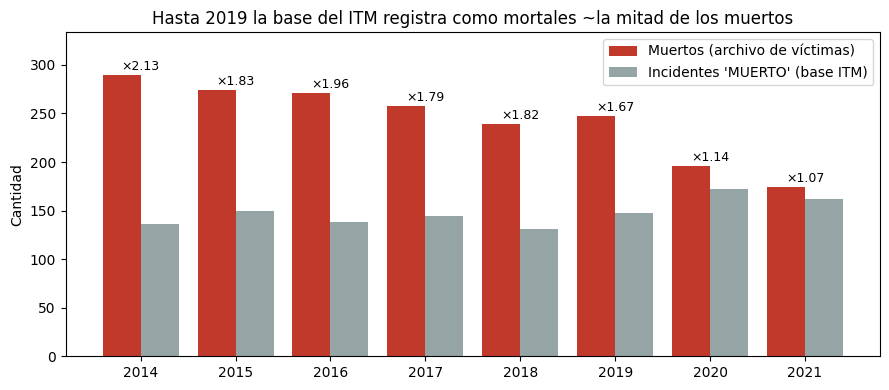

In [41]:
# 2.8 Muertos reales vs. incidentes mortales del ITM
c = comp.copy(); c.index = c.index.astype(int)
x = np.arange(len(c)); w = 0.4

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - w/2, c["muertos_victimas"], w, label="Muertos (archivo de víctimas)", color="#c0392b")
ax.bar(x + w/2, c["incidentes_mortales_itm"], w, label="Incidentes 'MUERTO' (base ITM)", color="#95a5a6")
for i, r in enumerate(c["razon"]):
    ax.text(i, c["muertos_victimas"].iloc[i] + 5, f"×{r}", ha="center", fontsize=9)
ax.set_xticks(x, c.index)
ax.set_ylim(0, c["muertos_victimas"].max() * 1.15)
ax.set_title("Hasta 2019 la base del ITM registra como mortales ~la mitad de los muertos")
ax.set_ylabel("Cantidad"); ax.legend()
plt.tight_layout(); plt.show()

### Conclusión – Parte 2 (Víctimas)

**Calidad del archivo**
- El archivo trae 1.048.317 filas, pero solo **235.843 son víctimas reales**; el resto son filas vacías de la exportación a Excel.
- Cubre de **ene-2014 a sep-2021**. 2021 está incompleto (9 meses).
- El `radicado` no permite unir con la base del ITM, porque el ITM no tiene esa columna. No hace falta unirlas: este archivo trae su propia dirección y coordenadas.

**Quién muere**
- **El 91% de los muertos son peatones (45,7%) o motociclistas con sus acompañantes (45,3%).** Le siguen los ciclistas (4,9%), los pasajeros (2,1%) y los conductores (2,0%).
- **Letalidad por actor:** de cada 100 peatones víctimas mueren 2,75; de cada 100 ciclistas, 1,8; de cada 100 motociclistas, 0,5. El peatón tiene una letalidad 5,5 veces mayor que la moto.
- La moto pesa por **volumen** (178 mil víctimas, el 76% de todas) y el peatón por **gravedad**.

**Tendencia**
- Los muertos peatones **bajaron 25%** entre 2015 y 2019 (de 145 a 109).
- Los muertos en moto **no bajaron**: siguen entre 107 y 127 por año.
- Desde 2016 la moto empata o supera al peatón. En 2021, llevado a año completo, la supera: ~115 contra ~89.
- En la pandemia (2020) los muertos peatones cayeron más que los de moto: menos gente caminando, pero los domicilios siguieron.

**Subregistro de muertos en la base del ITM**
- Entre 2014 y 2019, el archivo de víctimas cuenta entre **1,7 y 2,1 veces** más muertos que los incidentes marcados "MUERTO" en el ITM. En 2020–2021 la razón baja a ~1,1.
- Un incidente con varios muertos no alcanza a explicar una razón de 2. Lo más probable es que, antes de 2020, quien moría después en el hospital quedara registrado como "HERIDO".
- En consecuencia, el pico de 2022 de la Parte 1 (+45%) sería un efecto del registro, no un aumento real.

**Implicaciones para el proyecto**
- La reducción de velocidad protege sobre todo al peatón (la víctima más letal). El carril exclusivo ataca la parte del problema que Medellín no ha logrado bajar: la moto.
- Usar incidentes graves (D8) protege los modelos del subregistro: un muerto mal registrado como herido sigue contando como grave.
- La etiqueta "mortal" del ITM antes de 2020 no es confiable para la regresión logística ni para contar vidas salvadas.

### Decisión
- **D12:** se usan las 235.843 víctimas reales (2014 a sep-2021) para saber quién muere y para el riesgo de motos. No se unen con la base del ITM.
- **D13 (pendiente de confirmar con la Parte 4):** los muertos para calcular vidas salvadas salen de conteos oficiales (víctimas / mortalidad del Distrito), no de "MUERTO" del ITM. La regresión logística usará 2020 en adelante o se ajustará por el subregistro.
- **P2 → opción B:** riesgo de motos por corredor = % de víctimas graves que iban en moto, calculado con la dirección del archivo de víctimas.

## 3 · Incidentes viales con motos · MEData

#### 3.1 Carga y estructura

In [42]:
motos = normalizar_columnas(leer("motos_medata"))
print(motos.shape)
print(list(motos.columns))
motos.head()

Descargando motos_medata (~22 MB) desde la URL…
(223439, 9)
['nro_radicado', 'ano_incidente', 'fecha_incidente', 'hora_incidente', 'clase_incidente', 'gravedad_incidente', 'direccion', 'zona', 'diseno_via']


,nro_radicado,ano_incidente,fecha_incidente,hora_incidente,clase_incidente,gravedad_incidente,direccion,zona,diseno_via
0,1471551,2015,10/01/2015,23:23:00,Choque,HERIDO,Carrera 80 Con Calle 44 B,COMUNA 12,Tramo de via
1,1471559,2015,10/01/2015,20:00:00,Atropello,HERIDO,Carrera 111 Con Calle 34 CC,COMUNA 13,Tramo de via
2,1471643,2015,10/01/2015,17:40:00,Choque,SOLO DA\xD1OS,Carrera 49 Con Calle 79,COMUNA 4,Tramo de via\r
3,1471663,2015,10/01/2015,20:20:00,Choque,SOLO DA\xD1OS,Calle 30 Con Carrera 79 A,COMUNA 16,Tramo de via\r
4,1471664,2015,10/01/2015,14:50:00,Choque,SOLO DA\xD1OS,Calle 44 A Con Carrera 73,COMUNA 11,Ciclo Ruta\r


#### 3.2 Por año y gravedad

In [43]:
pd.crosstab(motos["ano_incidente"], motos["gravedad_incidente"])

gravedad_incidente,HERIDO,MUERTO,SOLO DA\xD1OS
ano_incidente,,,
2015,28629,119,6718
2016,29943,129,7269
2017,28295,147,7034
2018,25332,117,6933
2019,27697,143,7161
2020,21274,144,4853
2021,17422,108,3972


In [45]:
# 3.3 Limpieza, peso de la moto y unión con la base del ITM
motos["gravedad_incidente"] = motos["gravedad_incidente"].str.replace(r"SOLO DA.*OS", "SOLO DAÑOS", regex=True)
motos["diseno_via"] = motos["diseno_via"].str.strip()

# a) ¿Qué parte de los incidentes graves del ITM tiene moto?
graves = ["HERIDO", "MUERTO"]
peso = pd.DataFrame({
    "graves_motos": motos[motos["gravedad_incidente"].isin(graves)].groupby("ano_incidente").size(),
    "graves_itm": itm[itm["gravedad_incidente"].isin(graves)].groupby(itm["ano"].astype(int)).size(),
}).loc[2015:2021]
peso["pct_con_moto"] = (peso["graves_motos"] / peso["graves_itm"] * 100).round(1)
print(peso, "\n")

# b1) ¿La 'llave' del ITM es el radicado?
def como_texto(s):
    return s.astype(str).str.strip().str.replace(r"\.0$", "", regex=True)

print("Ejemplos de llave ITM:", itm["llave"].head(3).tolist())
print("Ejemplos de radicado motos:", motos["nro_radicado"].head(3).tolist())
por_radicado = como_texto(motos["nro_radicado"]).isin(set(como_texto(itm["llave"])))
print(f"Unión por radicado: {por_radicado.mean()*100:.1f}%")

# b2) Respaldo: unión por fecha + hora + dirección
def llave_union(df, fecha, hora, direc):
    f = pd.to_datetime(df[fecha], dayfirst=True, errors="coerce").dt.strftime("%Y-%m-%d")
    h = pd.to_datetime(df[hora].astype(str), format="mixed", errors="coerce").dt.strftime("%H:%M")
    d = df[direc].astype(str).str.upper().str.replace(r"\s+", " ", regex=True).str.strip()
    return f + "|" + h + "|" + d

por_fhd = llave_union(motos, "fecha_incidente", "hora_incidente", "direccion").isin(
    set(llave_union(itm, "fecha_incidente", "hora_incidente", "direccion_interpolada")))
print(f"Unión por fecha+hora+dirección: {por_fhd.mean()*100:.1f}%")
print("Por año (radicado):", (por_radicado.groupby(motos["ano_incidente"]).mean() * 100).round(1).to_dict(), "\n")

# c) Letalidad por diseño de vía
dv = pd.crosstab(motos["diseno_via"], motos["gravedad_incidente"])
dv["graves"] = dv["HERIDO"] + dv["MUERTO"]
dv["letalidad_%"] = (dv["MUERTO"] / dv["graves"] * 100).round(2)
dv.sort_values("graves", ascending=False)

      graves_motos  graves_itm  pct_con_moto
2015       28748.0       26061         110.3
2016       30072.0       26856         112.0
2017       28442.0       25328         112.3
2018       25449.0       23015         110.6
2019       27840.0       25233         110.3
2020       21418.0       19062         112.4
2021       17530.0       23813          73.6 

Ejemplos de llave ITM: [1, 2, 3]
Ejemplos de radicado motos: [1471551, 1471559, 1471643]
Unión por radicado: 0.0%
Unión por fecha+hora+dirección: 35.6%
Por año (radicado): {2015: 0.0, 2016: 0.0, 2017: 0.0, 2018: 0.0, 2019: 0.0, 2020: 0.0, 2021: 0.0} 



gravedad_incidente,HERIDO,MUERTO,SOLO DAÑOS,graves,letalidad_%
diseno_via,,,,,
Tramo de via,102090,649,0,102739,0.63
Lote o Predio,34779,15,0,34794,0.04
Interseccion,26187,123,0,26310,0.47
Tramo de via\r,8008,62,30677,8070,0.77
Glorieta,2117,9,0,2126,0.42
Lote o Predio\r,1462,1,800,1463,0.07
Interseccion\r,1076,12,9986,1088,1.10
Paso Elevado,894,13,0,907,1.43
Puente,658,8,0,666,1.20


Radicados repetidos en motos (%): 23.6


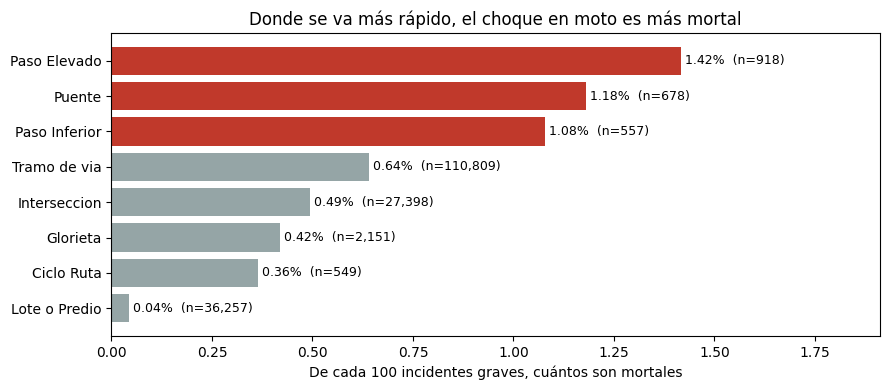

gravedad_incidente,HERIDO,MUERTO,SOLO DAÑOS,graves,letalidad_%
diseno_via,,,,,
Lote o Predio,36241,16,800,36257,0.04
Ciclo Ruta,547,2,159,549,0.36
Glorieta,2142,9,1627,2151,0.42
Interseccion,27263,135,9986,27398,0.49
Tramo de via,110098,711,30677,110809,0.64
Paso Inferior,551,6,114,557,1.08
Puente,670,8,240,678,1.18
Paso Elevado,905,13,272,918,1.42


In [46]:
# 3.4 Diseño de vía limpio + verificación de duplicados
motos["diseno_via"] = (motos["diseno_via"].str.replace(r"\\r$", "", regex=True)
                       .str.replace(r"\\xF3", "ó", regex=True).str.strip())

print("Radicados repetidos en motos (%):", round(motos["nro_radicado"].duplicated().mean() * 100, 1))

dv = pd.crosstab(motos["diseno_via"], motos["gravedad_incidente"])
dv["graves"] = dv["HERIDO"] + dv["MUERTO"]
dv["letalidad_%"] = dv["MUERTO"] / dv["graves"] * 100
dv = dv[dv["graves"] >= 500].sort_values("letalidad_%")   # solo categorías con datos suficientes

fig, ax = plt.subplots(figsize=(9, 4))
colores = ["#c0392b" if v > 1 else "#95a5a6" for v in dv["letalidad_%"]]
ax.barh(dv.index, dv["letalidad_%"], color=colores)
for i, (v, n) in enumerate(zip(dv["letalidad_%"], dv["graves"])):
    ax.text(v, i, f" {v:.2f}%  (n={n:,})", va="center", fontsize=9)
ax.set_xlim(0, dv["letalidad_%"].max() * 1.35)
ax.set_title("Donde se va más rápido, el choque en moto es más mortal")
ax.set_xlabel("De cada 100 incidentes graves, cuántos son mortales")
plt.tight_layout(); plt.show()
dv.round(2)

In [47]:
# 3.5 Una fila por incidente
motos_u = motos.drop_duplicates("nro_radicado")
print("Incidentes únicos con moto:", len(motos_u))

peso_u = pd.DataFrame({
    "graves_motos": motos_u[motos_u["gravedad_incidente"].isin(graves)].groupby("ano_incidente").size(),
    "graves_itm": itm[itm["gravedad_incidente"].isin(graves)].groupby(itm["ano"].astype(int)).size(),
}).loc[2015:2021]
peso_u["pct_con_moto"] = (peso_u["graves_motos"] / peso_u["graves_itm"] * 100).round(1)
print(peso_u, "\n")

dv_u = pd.crosstab(motos_u["diseno_via"], motos_u["gravedad_incidente"])
dv_u["graves"] = dv_u["HERIDO"] + dv_u["MUERTO"]
dv_u["letalidad_%"] = (dv_u["MUERTO"] / dv_u["graves"] * 100).round(2)
dv_u[dv_u["graves"] >= 500].sort_values("letalidad_%", ascending=False)

Incidentes únicos con moto: 170705
      graves_motos  graves_itm  pct_con_moto
2015       22064.0       26061          84.7
2016       23028.0       26856          85.7
2017       21646.0       25328          85.5
2018       19343.0       23015          84.0
2019       21232.0       25233          84.1
2020       16455.0       19062          86.3
2021       13236.0       23813          55.6 



gravedad_incidente,HERIDO,MUERTO,SOLO DAÑOS,graves,letalidad_%
diseno_via,,,,,
Paso Elevado,697,9,213,706,1.27
Puente,514,6,177,520,1.15
Tramo de via,84146,538,23535,84684,0.64
Interseccion,20817,101,7639,20918,0.48
Glorieta,1630,7,1247,1637,0.43
Lote o Predio,27513,11,617,27524,0.04


### Conclusión – Parte 3 (Incidentes viales con motos)

**Calidad del archivo**
- 223.439 filas entre 2015 y 2021, con radicado, fecha, hora, dirección, comuna y **diseño de vía**.
- **Hay una fila por vehículo, no por incidente:** el 23,6% de los radicados se repite (por ejemplo, un choque entre dos motos aparece dos veces). Sin repetidos quedan **170.705 incidentes**.
- Hubo que limpiar la codificación ("SOLO DA\xD1OS", "Pont\xF3n") y un "\r" literal en `diseno_via`. El "\r" aparece casi siempre en los solo daños, que parecen venir de otra exportación.
- 2021 está incompleto en esta base.

**No se puede unir con la base del ITM**
- La `llave` del ITM es un consecutivo (1, 2, 3…), no el radicado: la unión por radicado da 0%.
- Por fecha + hora + dirección solo coincide el 35,6%, porque la dirección del ITM está interpolada.
- Por eso no se puede marcar qué incidentes del ITM tienen moto.

**El peso de la moto**
- **Entre el 84% y el 86% de los incidentes graves de Medellín involucran una moto**, de forma estable entre 2015 y 2020. 2021 (55,6%) se excluye por estar incompleto.
- Hay ~131 incidentes mortales con moto por año (2015–2019), más que los motociclistas muertos (~115, Parte 2). La diferencia probablemente son peatones atropellados por motos: "incidente con moto" no es lo mismo que "víctima en moto".

**Tendencia**
- Los incidentes graves con moto son estables entre 2015 y 2019 y bajan en 2020–2021.
- **En 2020 hubo menos incidentes, pero más letales:** la letalidad pasó de 0,4–0,5% a 0,67%. Puede ser por las calles vacías (más velocidad) o por el cambio de registro de 2020 (Parte 2). Se separará con la velocidad de la Parte 5.

**Diseño de vía: la letalidad sube donde se va más rápido** (incidentes únicos)
| Diseño | Letalidad |
|---|---|
| Paso elevado | 1,27% |
| Puente | 1,15% |
| Tramo de vía | 0,64% |
| Intersección | 0,48% |
| Glorieta | 0,43% |
| Lote o predio | 0,04% |
- Un choque en un paso elevado es ~2 veces más mortal que en un tramo normal y ~3 veces más que en una intersección, donde se frena.
- Es **evidencia independiente de la hipótesis de velocidad**, sacada de una base que no usa ningún dato de velocidad.

### Decisión
- **D14:** la base de motos no se une con la del ITM. Se usa sin repetidos, para el peso de la moto (~85%) y para la letalidad por diseño de vía.
- **D15 (cierra P2):** el riesgo de motos por corredor = % de víctimas graves en moto, del archivo de víctimas, asignado al corredor por coordenadas.
- El diseño de vía no entra en la regresión logística sobre la base del ITM (no se puede unir), pero se presenta como evidencia de apoyo en el pitch.

## 4 · Mortalidad en vías · Observatorio de Movilidad (2019–2024)

#### 4.1 Carga y estructura

In [48]:
mort = normalizar_columnas(leer("mortalidad_distrito"))
mort["fecha"] = pd.to_datetime(mort["fecha_ocurrencia"], dayfirst=True, errors="coerce")
mort["ano"] = mort["fecha"].dt.year
print(mort.shape)
print(list(mort.columns))
mort.head()

(1541, 18)
['objectid', 'id', 'fecha_ocurrencia', 'hora_ocurrencia', 'fecha_levantamiento', 'direccion_ocurrencia', 'lugar_inspeccion', 'clase', 'sexo_fallecido', 'edad_fallecido', 'nom_comuna', 'latitud', 'longitud', 'lon_wgs84', 'lat_wgs84', 'shape', 'fecha', 'ano']


,objectid,id,fecha_ocurrencia,hora_ocurrencia,fecha_levantamiento,direccion_ocurrencia,lugar_inspeccion,clase,sexo_fallecido,edad_fallecido,nom_comuna,latitud,longitud,lon_wgs84,lat_wgs84,shape,fecha,ano
0,1,A000922553,1/01/2019,13:58:00,2019-01-01 00:00:00,CR 52 CL 31 - 83,Vía Pública,Choque,M,24,Belén,6.235068,-75.577223,-75.577223,6.235068,NaN,2019-01-01,2019
1,2,A000922548,1/01/2019,09:05:00,2019-01-01 00:00:00,CL 30 CR 78,Centro Asistencial,Choque,M,35,Belén,6.231222,-75.598215,-75.598215,6.231222,NaN,2019-01-01,2019
2,3,A000922581,2/01/2019,14:30:00,2019-01-06 00:00:00,CL 50 CR 74,Centro Asistencial,Atropello,M,55,Laureles Estadio,6.260386,-75.590256,-75.590256,6.260386,NaN,2019-01-02,2019
3,4,A000922944,6/01/2019,13:40:00,2019-01-06 00:00:00,CR 102 B CL 48A - 04,Centro Asistencial,Atropello,M,76,San Javier,6.259218,-75.618195,-75.618195,6.259218,NaN,2019-01-06,2019
4,5,00290-1123510042,7/01/2019,13:10:00,2019-01-07 00:00:00,CR 94 B CL 63 - 161,Otros,Choque,M,33,Robledo,6.279159,-75.606246,-75.606246,6.279159,NaN,2019-01-07,2019


#### 4.2 Validación: muertos por año, Distrito vs. base del ITM

In [49]:
comparacion = pd.DataFrame({
    "distrito_fallecidos": mort["ano"].value_counts(),
    "itm_incidentes_mortales": itm.loc[itm["gravedad_incidente"] == "MUERTO", "ano"].value_counts(),
}).loc[2019:2024]
comparacion["diferencia"] = comparacion["distrito_fallecidos"] - comparacion["itm_incidentes_mortales"]
comparacion

,distrito_fallecidos,itm_incidentes_mortales,diferencia
ano,,,
2019,251.0,148,103.0
2020,200.0,172,28.0
2021,253.0,162,91.0
2022,247.0,226,21.0
2023,277.0,160,117.0
2024,313.0,164,149.0


#### 4.3 Clase de incidente de los fallecidos

In [50]:
mort["clase"].value_counts()

clase
Choque            819
Atropello         658
Caída Ocupante     40
Volcamiento         9
                    9
Otros               3
Sumersión           2
Incendio            1
Name: count, dtype: int64

lugar_inspeccion  Centro Asistencial  Domicilio  Funeraria  Otros  Residencia  \
ano                                                                             
2019                             140          0          0      2           0   
2020                             110          0          0      3           0   
2021                             123          0          0      4           0   
2022                             119          0          0      3           0   
2023                             161          1          1      5           2   
2024                             164          3          0      1           3   

lugar_inspeccion  Sin Información  Vía Pública  
ano                                             
2019                            0          109  
2020                            2           85  
2021                           14          112  
2022                            0          125  
2023                            0          107  
2024    

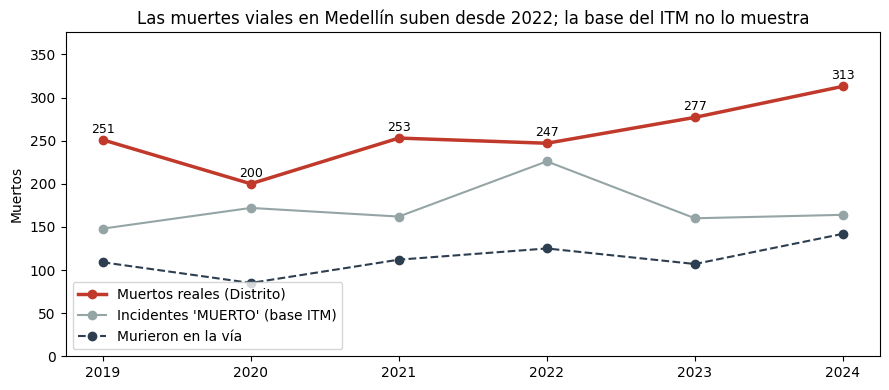

In [61]:
# 4.4 ¿Dónde murieron? ¿Qué cuenta realmente la base del ITM?
mort["ano"] = pd.to_numeric(mort["ano"], errors="coerce").astype("Int64")
lugar = pd.crosstab(mort["ano"], mort["lugar_inspeccion"])
print(lugar, "\n")

comp4 = comparacion.copy()
comp4.index = comp4.index.astype(int)
comp4["via_publica"] = lugar["Vía Pública"].reindex(comp4.index)
comp4["cobertura_itm_%"] = (comp4["itm_incidentes_mortales"] / comp4["distrito_fallecidos"] * 100).round(1)
comp4["pct_en_via"] = (comp4["via_publica"] / comp4["distrito_fallecidos"] * 100).round(1)
print(comp4, "\n")

lat = pd.to_numeric(mort["lat_wgs84"], errors="coerce")
lon = pd.to_numeric(mort["lon_wgs84"], errors="coerce")
dentro = lat.between(6.1, 6.4) & lon.between(-75.7, -75.5)
print(f"Fallecidos con coordenadas dentro de Medellín: {dentro.mean()*100:.1f}%")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(comp4.index, comp4["distrito_fallecidos"], marker="o", color="#c0392b", lw=2.5, label="Muertos reales (Distrito)")
ax.plot(comp4.index, comp4["itm_incidentes_mortales"], marker="o", color="#95a5a6", label="Incidentes 'MUERTO' (base ITM)")
ax.plot(comp4.index, comp4["via_publica"], marker="o", ls="--", color="#2c3e50", label="Murieron en la vía")
for x, y in zip(comp4.index, comp4["distrito_fallecidos"]):
    ax.text(x, y + 8, int(y), ha="center", fontsize=9)
ax.set_ylim(0, comp4["distrito_fallecidos"].max() * 1.2)
ax.set_xticks(comp4.index)
ax.set_title("Las muertes viales en Medellín suben desde 2022; la base del ITM no lo muestra")
ax.set_ylabel("Muertos"); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

### Conclusión – Parte 4 (Mortalidad del Distrito)

**Calidad del archivo**
- 1.541 fallecidos entre 2019 y 2024, con fecha, hora, dirección, clase, sexo, edad, comuna, **lugar de la muerte** y coordenadas.
- Es la cifra oficial y coincide con el archivo de víctimas (2019: 251 contra 247).

**La base del ITM subregistra los muertos, y de forma irregular**
| Año | Distrito | ITM | ITM / Distrito |
|---|---|---|---|
| 2019 | 251 | 148 | 59% |
| 2020 | 200 | 172 | 86% |
| 2021 | 253 | 162 | 64% |
| 2022 | 247 | 226 | 91% |
| 2023 | 277 | 160 | 58% |
| 2024 | 313 | 164 | 52% |
- La cobertura cambia entre el 52% y el 91% según el año. No se puede corregir con un factor fijo.
- **El pico de 2022 de la Parte 1 no era real:** ese año hubo los mismos muertos que en 2019 (247), pero el ITM registró más.
- El ITM no cuenta solo las muertes en el sitio: registra más que los muertos en la vía (85–142 por año), pero menos que el total.

**Las muertes viales en Medellín están subiendo**
- Fueron 247 en 2022, 277 en 2023 y **313 en 2024: +27% en dos años**, la cifra más alta de la serie.
- La base del ITM no muestra esta subida (160 y 164).

**Dónde y cómo mueren**
- **Solo ~4 de cada 10 muertos mueren en la vía;** el resto muere después, en un centro asistencial u otro lugar.
- Choque 53% y atropello 43%. En el ITM el atropello pesaba 35%: los peatones atropellados son los que más se pierden en el registro.

### Decisión
- **D13 (confirmada):** la base del ITM no se usa para contar muertos. Las vidas salvadas se calculan con los muertos del Distrito (2019–2024) y del archivo de víctimas (2014–2021). La base del ITM se queda para los incidentes graves (D8).
- **D16:** la regresión logística ("¿qué hace que una víctima muera?") se hace sobre el archivo de víctimas (2014 a sep-2021), cuya etiqueta coincide con la cifra oficial. No se hace sobre la base del ITM.
- **D17:** los muertos por

## 5 · Velocidad y tiempo de viaje · Google Traffic (MEData)

#### 5.1 Carga y estructura

In [51]:
gt = normalizar_columnas(leer("velocidad_gt"))
print(gt.shape)
print(list(gt.columns))
gt.head()

(682502, 20)
['id', 'fecha_hora', 'tv_s', 'corredor', 'dia', 'mes', 'ano', 'hora', 'fecha', 'nombre_corredor', 'flujo_tipo', 'sentido', 'inicio', 'fin', 'longitud_km', 'tv_minutos', 'velocidad_km_h', 'tv_min_km', 'diasem', 'nombre_dia']


,id,fecha_hora,tv_s,corredor,dia,mes,ano,hora,fecha,nombre_corredor,flujo_tipo,sentido,inicio,fin,longitud_km,tv_minutos,velocidad_km_h,tv_min_km,diasem,nombre_dia
0,1210,1/02/2017 6:00,377,2,1,2,2017,6,1/02/2017,Avenida Regional,Continuo,SN,Tugo,San Juan,6.6,6.3,63.0,1.0,3,Mi�rcoles
1,1212,1/02/2017 6:00,495,4,1,2,2017,6,1/02/2017,Autopista Sur,Continuo,NS,CTI,Calle 10,6.5,8.3,47.0,1.3,3,Mi�rcoles
2,1213,1/02/2017 6:00,495,5,1,2,2017,6,1/02/2017,Autopista Norte,Continuo,NS,Solla,Punto Cero,5.3,8.3,39.0,1.6,3,Mi�rcoles
3,1214,1/02/2017 6:00,401,6,1,2,2017,6,1/02/2017,Autopista Norte,Continuo,SN,Punto Cero,Solla,5.3,6.7,48.0,1.3,3,Mi�rcoles
4,1215,1/02/2017 6:00,693,7,1,2,2017,6,1/02/2017,Avenida 80,Interrumpido,NS,Calle 65,Calle 30,5.1,11.6,26.0,2.3,3,Mi�rcoles


#### 5.2 Años y horas cubiertas

In [52]:
print(gt["ano"].value_counts().sort_index())
print("Horas:", sorted(gt["hora"].unique()))

ano
2017    124619
2018    206000
2019    214761
2020    137122
Name: count, dtype: int64
Horas: [np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20)]


#### 5.3 Tramos: longitud y velocidad media

In [53]:
tramos = (gt.groupby(["nombre_corredor", "sentido"])
            .agg(longitud_km=("longitud_km", "mean"),
                 vel_media=("velocidad_km_h", "mean"),
                 vel_p85=("velocidad_km_h", lambda v: v.quantile(0.85)),
                 pct_horas_sobre_50=("velocidad_km_h", lambda v: (v > 50).mean() * 100))
            .round(1)
            .sort_values("vel_media", ascending=False))
print(f"{tramos.index.get_level_values(0).nunique()} corredores · {len(tramos)} tramos")
tramos

12 corredores · 22 tramos


longitud_km  vel_media  vel_p85  \
nombre_corredor     sentido                                    
Avenida Regional    SN               6.6       53.7     66.0   
Autopista Norte     NS               5.3       48.4     55.8   
Autopista Sur       NS               6.5       45.6     58.0   
Autopista Norte     SN               5.3       43.4     53.4   
Avenida Las Palmas  SN               6.0       42.0     48.0   
                    NS               5.9       39.9     45.0   
Avenida Guayabal    NS               4.1       35.5     40.5   
Avenida 33          WE               2.6       30.6     36.3   
Avenida Guayabal    SN               4.1       29.5     37.0   
Avenida 33          EW               2.5       27.2     34.0   
Avenida San Juan    WE               2.5       23.8     28.0   
Avenida 80          NS               5.1       22.6     28.0   
Avenida El Poblado  SN               3.8       22.4     29.1   
Avenida San Juan    EW               2.5       22.1     27.0   
Avenida 80          SN               5.1       21.8     28.0   
Calle 30            EW               2.9       20.8     27.0   
Avenida El Poblado  NS               3.8       20.8     27.4   
Calle 30            WE               2.9       20.7     25.6   
Avenida Ferrocarril NS               2.3       20.3     27.6   
                    SN               2.3       18.7     26.0   
Avenida Oriental    NS               1.6       14.9     20.0   
                    SN               1.6       13.6     19.0   

                             pct_horas_sobre_50  
nombre_corredor     sentido                      
Avenida Regional    SN                     71.1  
Autopista Norte     NS                     49.4  
Autopista Sur       NS                     44.7  
Autopista Norte     SN                     29.8  
Avenida Las Palmas  SN                      3.8  
                    NS                      0.1  
Avenida Guayabal    NS                      0.0  
Avenida 33          WE                      0.0  
Avenida Guayabal    SN                      0.0  
Avenida 33          EW                      0.0  
Avenida San Juan    WE                      0.0  
Avenida 80          NS                      0.0  
Avenida El Poblado  SN                      0.0  
Avenida San Juan    EW                      0.0  
Avenida 80          SN                      0.0  
Calle 30            EW                      0.0  
Avenida El Poblado  NS                      0.0  
Calle 30            WE                      0.0  
Avenida Ferrocarril NS                      0.0  
                    SN                      0.0  
Avenida Oriental    NS                      0.0  
                    SN                      0.0

#### 5.4 Velocidad media por hora del día

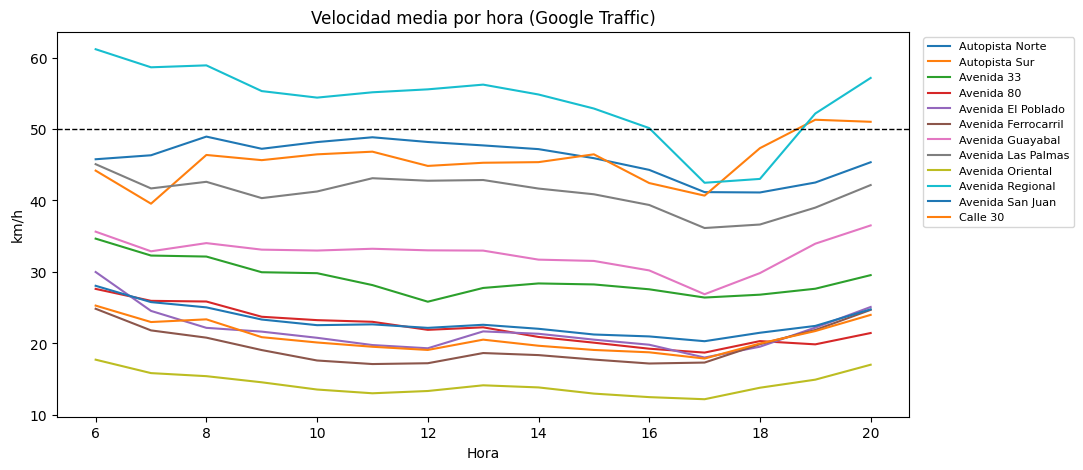

In [54]:
perfil = gt.pivot_table(index="hora", columns="nombre_corredor", values="velocidad_km_h", aggfunc="mean")
ax = perfil.plot(figsize=(11, 5), title="Velocidad media por hora (Google Traffic)")
ax.set_xlabel("Hora"); ax.set_ylabel("km/h"); ax.axhline(50, color="black", ls="--", lw=1)
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.show()

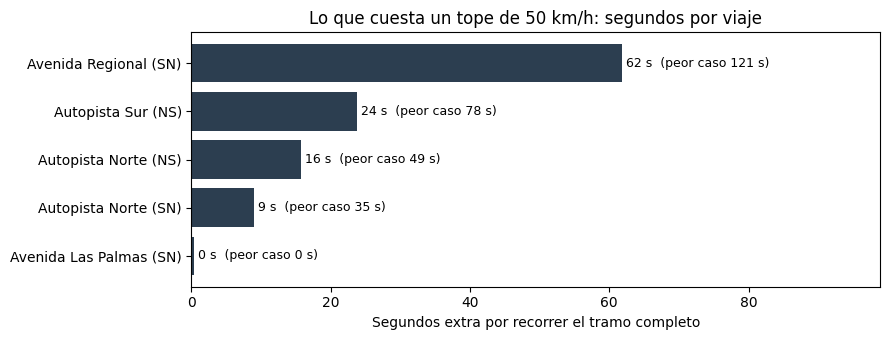

                            longitud_km  seg_extra_medio  seg_extra_p90
nombre_corredor    sentido                                             
Avenida Las Palmas SN               6.0              0.4            0.0
Autopista Norte    SN               5.3              9.0           34.7
                   NS               5.3             15.7           48.6
Autopista Sur      NS               6.5             23.7           78.0
Avenida Regional   SN               6.6             61.8          120.6


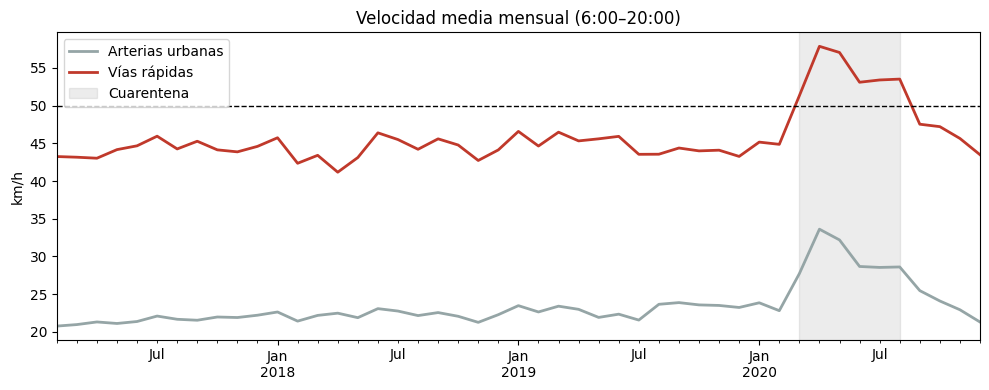

grupo  Arterias urbanas  Vías rápidas
mes                                  
2017               21.5          44.2
2018               22.2          44.1
2019               23.0          44.8
2020               26.6          50.0


In [62]:
# 5.4 a) ¿Cuántos segundos costaría un tope de 50 km/h? (estimación preliminar; la oficial es la función de Johan)
g = gt[gt["velocidad_km_h"] > 0].copy()
g["seg_actual"] = g["longitud_km"] / g["velocidad_km_h"] * 3600
g["seg_tope50"] = g["longitud_km"] / g["velocidad_km_h"].clip(upper=50) * 3600
g["seg_extra"] = g["seg_tope50"] - g["seg_actual"]

costo = (g.groupby(["nombre_corredor", "sentido"])
          .agg(longitud_km=("longitud_km", "first"),
               seg_extra_medio=("seg_extra", "mean"),
               seg_extra_p90=("seg_extra", lambda s: s.quantile(0.9)))
          .round(1).sort_values("seg_extra_medio"))
costo = costo[costo["seg_extra_medio"] > 0]

fig, ax = plt.subplots(figsize=(9, 3.5))
etiquetas = [f"{c} ({s})" for c, s in costo.index]
ax.barh(etiquetas, costo["seg_extra_medio"], color="#2c3e50")
for i, (m, p) in enumerate(zip(costo["seg_extra_medio"], costo["seg_extra_p90"])):
    ax.text(m, i, f" {m:.0f} s  (peor caso {p:.0f} s)", va="center", fontsize=9)
ax.set_xlim(0, costo["seg_extra_medio"].max() * 1.6)
ax.set_title("Lo que cuesta un tope de 50 km/h: segundos por viaje")
ax.set_xlabel("Segundos extra por recorrer el tramo completo")
plt.tight_layout(); plt.show()
print(costo)

# 5.4 b) ¿Se aceleró en 2020 con las calles vacías?
rapidas = ["Avenida Regional", "Autopista Norte", "Autopista Sur", "Avenida Las Palmas"]
g["grupo"] = np.where(g["nombre_corredor"].isin(rapidas), "Vías rápidas", "Arterias urbanas")
g["mes"] = pd.to_datetime(g["fecha"], dayfirst=True).dt.to_period("M").dt.to_timestamp()
mensual = g.groupby(["mes", "grupo"])["velocidad_km_h"].mean().unstack()

ax = mensual.plot(figsize=(10, 4), color={"Vías rápidas": "#c0392b", "Arterias urbanas": "#95a5a6"}, lw=2)
ax.axvspan(pd.Timestamp("2020-03-20"), pd.Timestamp("2020-08-31"), color="grey", alpha=0.15, label="Cuarentena")
ax.axhline(50, ls="--", color="black", lw=1)
ax.set_title("Velocidad media mensual (6:00–20:00)")
ax.set_ylabel("km/h"); ax.set_xlabel(""); ax.legend()
plt.tight_layout(); plt.show()
print(mensual.groupby(mensual.index.year).mean().round(1))

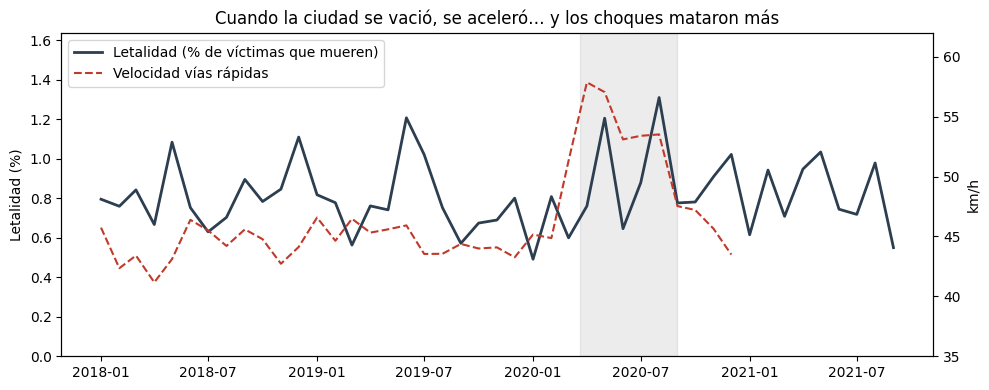

,victimas,muertos,letalidad_%
fecha,,,
Antes (2018–mar 2020),68433,535,0.78
Cuarentena (mar–ago 2020),7458,71,0.95
Después (sep 2020–sep 2021),30405,250,0.82


In [63]:
# 5.5 ¿La letalidad subió en los meses en que se aceleró? (archivo de víctimas)
v = vic[vic["fecha"].between("2018-01-01", "2021-09-30")].copy()
v["mes"] = v["fecha"].dt.to_period("M").dt.to_timestamp()
letal = v.groupby("mes")["gravedad_victima"].apply(lambda s: (s == "Muertos").mean() * 100)

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(letal.index, letal, color="#2c3e50", lw=2, label="Letalidad (% de víctimas que mueren)")
ax1.set_ylabel("Letalidad (%)")
ax1.set_ylim(0, letal.max() * 1.25)
ax2 = ax1.twinx()
vel = mensual["Vías rápidas"].loc["2018":]
ax2.plot(vel.index, vel, color="#c0392b", lw=1.5, ls="--", label="Velocidad vías rápidas")
ax2.set_ylabel("km/h"); ax2.set_ylim(35, 62)
ax1.axvspan(pd.Timestamp("2020-03-20"), pd.Timestamp("2020-08-31"), color="grey", alpha=0.15)
ax1.set_title("Cuando la ciudad se vació, se aceleró… y los choques mataron más")
lineas = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax1.legend(lineas, [l.get_label() for l in lineas], loc="upper left")
plt.tight_layout(); plt.show()

periodo = pd.cut(v["fecha"], [pd.Timestamp("2018-01-01"), pd.Timestamp("2020-03-19"),
                              pd.Timestamp("2020-08-31"), pd.Timestamp("2021-09-30")],
                 labels=["Antes (2018–mar 2020)", "Cuarentena (mar–ago 2020)", "Después (sep 2020–sep 2021)"])
resumen = v.groupby(periodo, observed=True)["gravedad_victima"].agg(
    victimas="size", muertos=lambda s: (s == "Muertos").sum())
resumen["letalidad_%"] = (resumen["muertos"] / resumen["victimas"] * 100).round(2)
resumen

In [64]:
# 5.6 Prueba formal y composición por actor
from statsmodels.stats.proportion import proportions_ztest

a, c = resumen.loc["Antes (2018–mar 2020)"], resumen.loc["Cuarentena (mar–ago 2020)"]
z, p = proportions_ztest([c["muertos"], a["muertos"]], [c["victimas"], a["victimas"]])
print(f"Cuarentena vs antes: z = {z:.2f}, p = {p:.3f}\n")

v["periodo"] = periodo
comp_actor = pd.crosstab(v["periodo"], v["actor"], normalize="index").mul(100).round(1)
print("% de víctimas por actor:\n", comp_actor, "\n")

let_actor = v.groupby(["periodo", "actor"], observed=True)["gravedad_victima"].apply(
    lambda s: (s == "Muertos").mean() * 100).unstack().round(2)
print("Letalidad por actor (%):\n", let_actor)

Cuarentena vs antes: z = 1.57, p = 0.117

% de víctimas por actor:
 actor                        Ciclista  Conductor  Moto  Pasajero  Peatón
periodo                                                                 
Antes (2018–mar 2020)             2.4        2.7  75.4       6.1    13.4
Cuarentena (mar–ago 2020)         3.4        2.7  79.3       3.5    11.1
Después (sep 2020–sep 2021)       2.9        2.3  78.3       4.4    12.1 

Letalidad por actor (%):
 actor                        Ciclista  Conductor  Moto  Pasajero  Peatón
periodo                                                                 
Antes (2018–mar 2020)            1.98       0.59  0.48      0.26    2.56
Cuarentena (mar–ago 2020)        1.17       0.50  0.63      0.39    3.51
Después (sep 2020–sep 2021)      1.60       1.17  0.50      0.44    2.79


### Conclusión – Parte 5 (Google Traffic)

**Calidad del archivo**
- 682.502 registros de 12 corredores, de feb-2017 a dic-2020, **solo de 6:00 a 20:00** (no hay noche).
- Mide la **velocidad media del tramo completo**, con semáforos y frenadas incluidos. Subestima la velocidad puntual en las rectas.
- La Autopista Sur solo tiene el sentido norte-sur.

**Hay dos tipos de corredor**
- **Vías rápidas:** Regional (53,7 km/h; pasa de 50 en el 71% de las horas), Autopista Norte (48 y 43), Autopista Sur (45,6) y Las Palmas (40–42).
- **Arterias urbanas:** la 33, la 80, San Juan, El Poblado, la Calle 30, la Ferrocarril, Guayabal y la Oriental. Van a 14–35 km/h y nunca pasan de 50 de día.
- **Un tope de 50 km/h como el de Bogotá solo actúa en las vías rápidas.** En las arterias, la congestión ya hace que se vaya despacio.

**Perfil por hora**
- La velocidad mínima es a las 5 p. m. y sube en la mañana temprano y hacia la noche (Regional: 61 km/h a las 6 a. m. y 57 a las 8 p. m.).
- Coincide con la Parte 1: la letalidad pasa del 0,5% de día al 2,8% a las 3 a. m. El riesgo está en las horas sin congestión, que esta fuente no cubre (Parte 6).

**Costo en tiempo de un tope de 50 km/h** (estimación preliminar)
| Corredor | Segundos extra (media) | Peor caso (p90) |
|---|---|---|
| Regional SN | 62 | 121 |
| Autopista Sur NS | 24 | 78 |
| Autopista Norte NS | 16 | 49 |
| Autopista Norte SN | 9 | 35 |
| Las Palmas SN | 0 | 0 |
- **El costo máximo es de un minuto por viaje en promedio.** Son literalmente *segundos contra vidas*.

**La cuarentena como experimento natural**
- Con las calles vacías, las vías rápidas pasaron de ~45 a 58 km/h (+29%) y las arterias, de ~23 a 34 km/h (+45%). En septiembre de 2020 volvieron a los niveles normales.
- La letalidad general pasó de **0,78% antes a 0,95% en la cuarentena (+22%) y 0,82% después.**
- **Por actor, el efecto es mayor:** moto de 0,48% a 0,63% (+31%); peatón de 2,56% a 3,51% (+37%). Los dos vuelven a bajar después de la cuarentena.
- El promedio sube menos porque en la cuarentena había menos peatones (13,4% → 11,1% de las víctimas), el actor más letal.
- No es estadísticamente significativo (p = 0,117; solo 71 muertos en la cuarentena). Es **evidencia consistente**, no prueba.
- El exponente implícito sobre la letalidad es ~1, la mitad del que predice Nilsson (~2). Se contrastará con la binomial negativa.

### Decisión
- **D18:** la reducción de velocidad se evalúa solo en las vías rápidas (Regional, Autopista Norte, Autopista Sur, Las Palmas) de día, y en todos los corredores de noche (Parte 6).
- **D19:** la cuarentena se presenta como evidencia consistente, no como prueba. Sirve para contrastar el exponente de la binomial negativa, no para fijarlo. Cualquier comparación de letalidad se hace **por actor**, no con el promedio, porque la composición cambia.

## 6 · Velocidad e intensidad vehicular · SIMM (MEData)

#### 6.1 Carga y estructura

In [65]:
simm = normalizar_columnas(leer("velocidad_simm"))
print(simm.shape)
print(list(simm.columns))
simm.head()

(431490, 25)
['carril', 'fecha_trafico', 'fecha', 'hora', 'dia', 'dia_num', 'mes_num', 'mes', 'ano', 'velocidad_km_h', 'corredor', 'sentido', 'operacion', 'intensidad', 'categoria_1', 'categoria_2', 'categoria_3', 'ocupacion', 'tipo_subsistema', 'longitud', 'latitud', 'identificador_f_v', 'comuna', 'codigo_comuna', 'nombre_comuna']


,carril,fecha_trafico,fecha,hora,dia,dia_num,mes_num,mes,ano,velocidad_km_h,corredor,sentido,operacion,intensidad,categoria_1,categoria_2,categoria_3,ocupacion,tipo_subsistema,longitud,latitud,identificador_f_v,comuna,codigo_comuna,nombre_comuna
0,XC-1-BOL-65-ENT:ORI-OCC,1/07/2020 0:00,1/07/2020,0,Miercoles,3,7,Julio,2020,27,Avenida Bolivariana,EW,interrumpido,148,136,9,3,15,ARS,"833291,8125","1182614,75",V,11 - Laureles Estadio,11,Laureles Estadio
1,XC-1-BOL-65-ENT:ORI-OCC,1/07/2020 1:00,1/07/2020,1,Miercoles,3,7,Julio,2020,24,Avenida Bolivariana,EW,interrumpido,73,71,2,0,3,ARS,"833291,8125","1182614,75",V,11 - Laureles Estadio,11,Laureles Estadio
2,XC-1-BOL-65-ENT:ORI-OCC,1/07/2020 2:00,1/07/2020,2,Miercoles,3,7,Julio,2020,21,Avenida Bolivariana,EW,interrumpido,48,46,1,1,4,ARS,"833291,8125","1182614,75",V,11 - Laureles Estadio,11,Laureles Estadio
3,XC-1-BOL-65-ENT:ORI-OCC,1/07/2020 3:00,1/07/2020,3,Miercoles,3,7,Julio,2020,18,Avenida Bolivariana,EW,interrumpido,60,54,5,1,11,ARS,"833291,8125","1182614,75",V,11 - Laureles Estadio,11,Laureles Estadio
4,XC-1-BOL-65-ENT:ORI-OCC,1/07/2020 4:00,1/07/2020,4,Miercoles,3,7,Julio,2020,18,Avenida Bolivariana,EW,interrumpido,91,84,4,3,16,ARS,"833291,8125","1182614,75",V,11 - Laureles Estadio,11,Laureles Estadio


#### 6.2 Años, horas y estado de operación

In [66]:
print(simm["ano"].value_counts().sort_index())
print("Horas:", sorted(simm["hora"].unique()))
print(simm["operacion"].value_counts())

ano
2020    431490
Name: count, dtype: int64
Horas: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]
operacion
interrumpido       274876
continuo            85425
seminterrumpido     33639
Name: count, dtype: int64


#### 6.3 Corredores y número de registros

In [57]:
simm.groupby("corredor").agg(registros=("velocidad_km_h", "size"),
                             vel_media=("velocidad_km_h", "mean"),
                             intensidad_media=("intensidad", "mean")).round(1).sort_values("registros", ascending=False)

,registros,vel_media,intensidad_media
corredor,,,
Avenida Las Vegas,48685,32.7,182.1
Avenida El Poblado,38838,25.8,182.6
Carrera 65,29560,17.1,175.0
Avenida Oriental,27953,18.1,158.1
Autopista Norte,26040,37.4,645.5
Avenida 80,22392,21.7,295.0
Avenida Regional,22278,42.1,602.3
Autopista Sur,19213,37.4,644.6
San Juan,16454,22.0,253.2


#### 6.4 Velocidad de día vs. de noche

In [58]:
simm["franja"] = pd.cut(simm["hora"], bins=[-1, 5, 19, 23], labels=["madrugada (0-5)", "día (6-19)", "noche (20-23)"])
simm.groupby("franja", observed=True)["velocidad_km_h"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
franja,,,,,,,,
madrugada (0-5),106580.0,27.7,16.4,0.0,17.0,25.0,34.0,205.0
día (6-19),253130.0,28.1,15.1,0.0,17.0,26.0,36.0,171.0
noche (20-23),71780.0,27.5,14.8,0.0,17.0,25.0,35.0,254.0


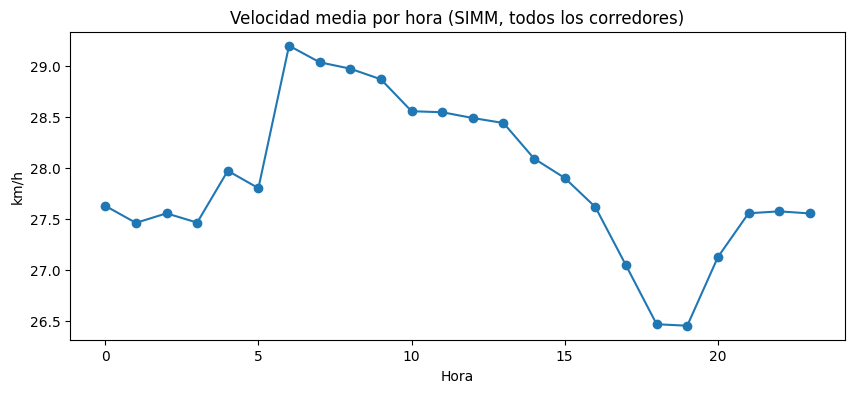

In [68]:
ax = simm.groupby("hora")["velocidad_km_h"].mean().plot(marker="o", figsize=(10, 4), title="Velocidad media por hora (SIMM, todos los corredores)")
ax.set_xlabel("Hora"); ax.set_ylabel("km/h")
plt.show()

Meses con datos: [np.int64(7), np.int64(8)]
Registros con velocidad 0 (%): {'madrugada (0-5)': 2.4, 'día (6-19)': 1.0, 'noche (20-23)': 0.8}
Registros válidos: 98.7%



C:\Users\crist\AppData\Local\Temp\ipykernel_3164\616685718.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  por_hora = s.groupby(["grupo", "hora"]).apply(lambda d: pd.Series({


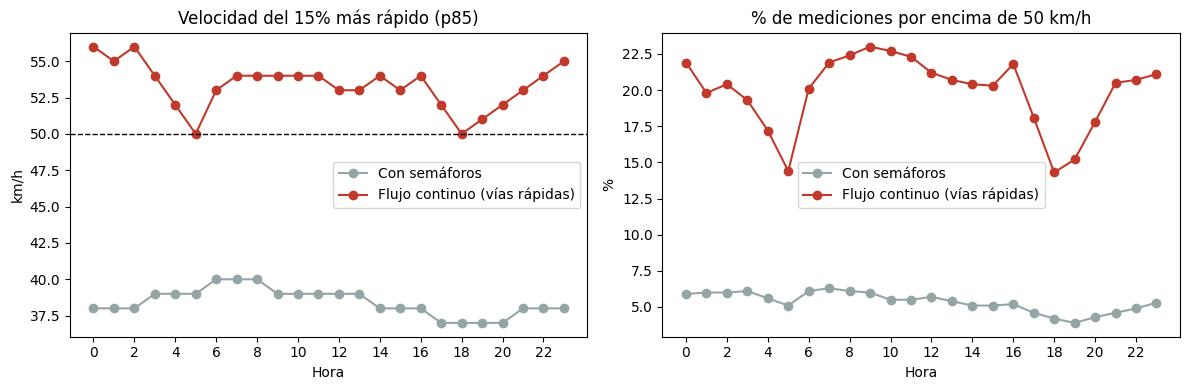

,vel_ponderada,vel_p85,pct_sobre_50,intensidad
hora,,,,
0,36.7,56.0,21.9,114.7
1,35.8,55.0,19.8,87.6
2,35.7,56.0,20.4,87.7
3,35.6,54.0,19.3,108.6
4,35.4,52.0,17.2,243.2
5,35.3,50.0,14.4,561.9
6,38.7,53.0,20.1,738.9
7,39.4,54.0,21.9,743.2
8,40.1,54.0,22.4,710.9


In [69]:
# 6.4 Velocidad nocturna depurada: sin ceros, por tipo de vía y mirando a los más rápidos
print("Meses con datos:", sorted(simm["mes_num"].unique()))
simm["franja"] = pd.cut(simm["hora"], [-1, 5, 19, 23], labels=["madrugada (0-5)", "día (6-19)", "noche (20-23)"])
print("Registros con velocidad 0 (%):",
      (simm["velocidad_km_h"].eq(0).groupby(simm["franja"], observed=True).mean() * 100).round(1).to_dict())

s = simm[(simm["velocidad_km_h"] > 0) & (simm["intensidad"] > 0) & (simm["velocidad_km_h"] < 150)].copy()
print(f"Registros válidos: {len(s) / len(simm) * 100:.1f}%\n")
s["grupo"] = np.where(s["operacion"] == "continuo", "Flujo continuo (vías rápidas)", "Con semáforos")

por_hora = s.groupby(["grupo", "hora"]).apply(lambda d: pd.Series({
    "vel_ponderada": np.average(d["velocidad_km_h"], weights=d["intensidad"]),
    "vel_p85": d["velocidad_km_h"].quantile(0.85),
    "pct_sobre_50": (d["velocidad_km_h"] > 50).mean() * 100,
    "intensidad": d["intensidad"].mean(),
})).round(1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
colores = {"Flujo continuo (vías rápidas)": "#c0392b", "Con semáforos": "#95a5a6"}
for grupo, d in por_hora.groupby(level=0):
    d = d.droplevel(0)
    ax1.plot(d.index, d["vel_p85"], marker="o", color=colores[grupo], label=grupo)
    ax2.plot(d.index, d["pct_sobre_50"], marker="o", color=colores[grupo], label=grupo)
ax1.axhline(50, ls="--", color="black", lw=1)
ax1.set_title("Velocidad del 15% más rápido (p85)"); ax1.set_xlabel("Hora"); ax1.set_ylabel("km/h")
ax2.set_title("% de mediciones por encima de 50 km/h"); ax2.set_xlabel("Hora"); ax2.set_ylabel("%")
for ax in (ax1, ax2):
    ax.set_xticks(range(0, 24, 2)); ax.legend()
plt.tight_layout(); plt.show()

por_hora.loc["Flujo continuo (vías rápidas)"]

#### 6.5 Categorías vehiculares (¿se pueden identificar motos?)

In [60]:
cats = simm[["intensidad", "categoria_1", "categoria_2", "categoria_3"]].apply(pd.to_numeric, errors="coerce")
print("¿categoria_1 + 2 + 3 = intensidad?:", round(((cats[["categoria_1", "categoria_2", "categoria_3"]].sum(axis=1)) == cats["intensidad"]).mean() * 100, 1), "% de las filas")
(cats[["categoria_1", "categoria_2", "categoria_3"]].sum() / cats["intensidad"].sum() * 100).round(1)

¿categoria_1 + 2 + 3 = intensidad?: 93.3 % de las filas


categoria_1    69.3
categoria_2     7.5
categoria_3     7.8
dtype: float64

### Conclusión – Parte 6 (Velocidad e intensidad SIMM)

**Calidad del archivo**
- 431.490 registros **solo de 2020** (meses: __), por carril y hora, en ~50 corredores, con **las 24 horas**.
- Trae velocidad, intensidad, tipo de operación (64% con semáforos, 20% flujo continuo, 8% semiinterrumpido) y tres categorías de vehículo.
- Hay registros con velocidad 0 (__% de madrugada) y valores imposibles (hasta 254 km/h). Se depuraron: quedan __% de registros válidos.
- La categoría 1 es el 69% del tráfico: probablemente "livianos" (carros y motos juntos). No sirve para aislar motos.
- Algunos nombres tienen la codificación dañada ("Vía al Túnel de Occidente").
- Mide la **velocidad promedio por carril y hora**, no por vehículo. Subestima a los conductores individuales más rápidos.

**En las vías rápidas se pasa de 50 todo el día**
- En flujo continuo, **~20% de las mediciones supera 50 km/h a cualquier hora**. Solo baja al 14% en las horas pico (5 a. m. y 6–7 p. m.). El p85 está en 53–56 km/h.
- En las vías con semáforos, el p85 es de 37–40 km/h y solo ~5% supera 50.

**La noche: poco más rápida, mucho más letal**
- De 0 a 2 a. m. el p85 sube a 56 km/h, contra 53–54 de día (+4%). El % sobre 50 es igual que de día.
- De noche hay ~7 veces menos tráfico (90–115 vehículos por carril y hora, contra ~750).
- Con Nilsson, un +4% de velocidad explica ~+17% de muertes, pero la letalidad de madrugada es **5,6 veces** la del día (Parte 1). **La velocidad explica solo una parte pequeña del riesgo nocturno.** El resto probablemente se debe a alcohol, cansancio, visibilidad y respuesta médica, que no están en los datos.

### Decisión
- **D18 (ajustada):** la reducción de velocidad se evalúa en las vías rápidas **a cualquier hora**, porque el exceso es constante. No se plantea como medida solo nocturna. En las arterias con semáforos no se evalúa, porque casi nadie pasa de 50.
- **D20:** la hora entra en los modelos como control (D11), no como efecto de la velocidad. El riesgo nocturno se reporta aparte como un hallazgo, con medidas complementarias (control de alcohol) fuera del alcance del modelo.
- **D21:** la velocidad nocturna por corredor sale del SIMM 2020 (p85 y % sobre 50, ponderado por intensidad). Es la única fuente con 24 horas.

## 7 · Resumen de la exploración

### Qué fuente sirve para qué
| Fuente | Cobertura real | Se usa para | No se usa para |
|---|---|---|---|
| **Base del ITM** (Mendeley) | 2008 – ago 2025 · 702.540 incidentes | **Incidentes graves** (herido + muerto) por corredor y hora: la variable del modelo | Contar muertos (subregistro del 9–48%) |
| **Víctimas** (MEData) | ene 2014 – sep 2021 · 235.843 víctimas | Quién muere (actor, edad, hora), **regresión logística**, riesgo de motos por corredor | Unirse con el ITM (no hay llave común) |
| **Incidentes con motos** (MEData) | 2015 – 2021 · 170.705 incidentes únicos | Peso de la moto (~85%), letalidad por diseño de vía | Contar ni unirse con el ITM (una fila por vehículo) |
| **Mortalidad del Distrito** (ArcGIS) | 2019 – 2024 · 1.541 fallecidos | **Muertos reales** por año y por corredor (línea base de vidas salvadas) | — |
| **Google Traffic** (MEData) | feb 2017 – dic 2020 · 12 corredores · 6:00–20:00 | Velocidad diurna por corredor, **costo en tiempo**, cuarentena | La noche (no la cubre) |
| **Velocidad SIMM** (MEData) | solo 2020 · ~50 corredores · 24 h | **Velocidad nocturna**, % sobre 50 km/h | Aislar motos (la categoría 1 parece "livianos") |
| Conteo SIMM | solo ene 2021 · 856 MB | — (D5) | — |

### Problemas de calidad encontrados y cómo se resolvieron
| Problema | Dónde | Solución |
|---|---|---|
| Los choques de solo daños casi desaparecen desde 2023 | ITM | Solo incidentes graves (D8) |
| 2025 solo trae enero–agosto | ITM | No se compara como año completo (D9) |
| Direcciones de relleno ("CALLE 999…", "N/D") y coordenadas fuera de la ciudad | ITM | Se tratan como faltantes; el 2,5% de los graves no se asigna a corredor (D10) |
| **La base del ITM registra solo el 52–91% de los muertos, y distinto cada año** | ITM vs Distrito | Los muertos salen del Distrito y del archivo de víctimas (D13) |
| 812 mil filas vacías por la exportación a Excel | Víctimas | Se filtran (D12) |
| Una fila por vehículo (23,6% de radicados repetidos) | Motos | Se usan incidentes únicos (D14) |
| Codificación dañada ("SOLO DA\xD1OS", "V���a al T���nel") y "\r" literal | Motos, SIMM | Limpieza de texto |
| Velocidades 0 y mayores de 150 km/h | SIMM | Se depuran (D21) |

### Hallazgos principales
1. **Las muertes viales en Medellín suben:** 247 en 2022, 277 en 2023 y **313 en 2024 (+27%)**, la cifra más alta de la serie. La base del ITM no lo muestra.
2. **El 91% de los muertos son peatones (46%) o motociclistas (45%).** El peatón es el más letal (2,75 muertos por cada 100 víctimas, 5,5 veces la moto); la moto pesa por volumen.
3. **8 de cada 10 incidentes graves involucran una moto** (84–86%, estable entre 2015 y 2020).
4. **Los muertos peatones bajaron 25% entre 2015 y 2019; los de moto no bajaron.** Desde 2016 la moto empata o supera al peatón.
5. **Donde se va más rápido, el choque mata más:** paso elevado 1,27% y puente 1,15%, contra 0,64% en un tramo normal y 0,48% en una intersección.
6. **Un tope de 50 km/h solo actúa en las vías rápidas** (Regional, Autopistas, Las Palmas). Ahí ~20% de las mediciones pasa de 50 a cualquier hora. En las arterias con semáforos casi nadie pasa de 50.
7. **El costo de la medida es de segundos:** 62 s en la Regional, 24 s en la Autopista Sur y 9–16 s en la Autopista Norte, por viaje y en promedio.
8. **La cuarentena actuó como experimento natural:** la velocidad subió +29% y la letalidad de la moto +31% y la del peatón +37%, que volvieron a bajar después. Es evidencia consistente, pero no significativa (p = 0,12).
9. **La madrugada es 5,6 veces más letal que el día, pero la velocidad explica solo una parte:** de noche el p85 sube apenas ~4%. El resto probablemente se debe a alcohol, cansancio, visibilidad y respuesta médica.
10. **Solo 4 de cada 10 muertos mueren en la vía;** el resto muere después, en un centro asistencial.

### Qué cambia para los modelos
| Modelo | Decisión tomada en la exploración |
|---|---|
| Tabla maestra (corredor × hora) | Incidentes graves del ITM + velocidad de Google Traffic (día) y del SIMM (noche) |
| **Exponente de Medellín** (binomial negativa) | Sobre incidentes graves, con el volumen como exposición y la hora como control (D11, D20). Se contrasta con la cuarentena (exponente implícito ~1 sobre la letalidad, contra ~2 de Nilsson) (D19) |
| **Regresión logística** | Sobre el archivo de víctimas: "¿qué hace que una víctima muera?" (actor, edad, hora, clase) (D16) |
| Predicción (XGBoost vs. estadístico) | Ventana 2017–2019, prueba 2021+ (D4) |
| **Monte Carlo de vidas salvadas** | Línea base de muertos por corredor del Distrito 2019–2024 (D17). Solo en las vías rápidas (D18) |
| Riesgo de motos por corredor | % de víctimas graves en moto, por coordenadas (D15) |

### Obsevaciones
- **Problema:** *"En 2024 murieron 313 personas en las vías de Medellín, la cifra más alta de la serie. Y la base de incidentes ni siquiera lo muestra."*
- **Problema:** *"8 de cada 10 incidentes graves involucran una moto, y es la única muerte que Medellín no ha logrado bajar."*
- **Datos:** *"Cruzamos 6 fuentes y encontramos que la base de incidentes pierde hasta la mitad de los muertos. Lo corregimos con la cifra oficial."*
- **Aporte:** *"Bajar a 50 km/h en la Regional cuesta un minuto por viaje. Ese es el precio."*